# Эксперименты TF-IDF + SGD: сохранённый прогресс

Этот notebook читает готовые JSON-замеры и строит графики. Он **не обучает модели**, не меняет данные и не публикует веса. Выходы ячеек сохранены для просмотра на GitHub.

Область: категории 102–106, исключение исходного mcId, пороги 0.5. Данные public имеют автоматическую разметку; v2 — синтетический стрессовый корпус. Серверная production-модель здесь не проверялась и не заменялась.

Последовательность: словесные триграммы → char_wb/лимиты словаря → v2 отдельно → public+v2 → парное сравнение старой/смешанной моделей на общих тестах.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'avito_compare').is_dir() and (p/'output').is_dir())
OUT = ROOT/'output/experiment-review'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 130, 'font.family': 'DejaVu Sans', 'axes.spines.top': False, 'axes.spines.right': False})
def read(path): return json.loads((ROOT/path).read_text())
def table(headers, rows):
    text = '| ' + ' | '.join(headers) + ' |\n| ' + ' | '.join(['---']*len(headers)) + ' |\n'
    text += '\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in rows)
    display(Markdown(text))
def save(fig, name):
    fig.savefig(OUT/name, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(OUT/name)))
ngrams = read('output/ngram-comparison/comparison.json')
features = read('output/tfidf-feature-experiments/summary.json')
mixed = read('output/mixed-charwb-comparison/evaluation.json')
paired = read('output/paired-data-evaluation/comparison.json')
lengths = read('output/dataset-length-comparison/stats.json')
assert all(m['thresholds'] == [0.5]*5 for m in features['measurements'].values())
print('Данные замеров загружены; обучение не выполнялось.')

Данные замеров загружены; обучение не выполнялось.


## 1. Словесные триграммы

Менялся только word ngram_range: (1,2) → (1,3). Символьный analyzer=char, те же train/calibration/test и параметры SGD. Прирост Micro-F1 небольшой; bootstrap-интервал включает ноль. Время — один fit, включая TF-IDF и SGD.

| Метрика | Биграммы | Триграммы | Абсолютная Δ | Относительная Δ, % |
| --- | --- | --- | --- | --- |
| Micro-F1 | 0.934646 | 0.936217 | +0.001571 | +0.168 |
| Macro-F1 | 0.934682 | 0.936225 | +0.001543 | +0.165 |
| Precision (micro) | 0.936438 | 0.939044 | +0.002606 | +0.278 |
| Recall (micro) | 0.932860 | 0.933406 | +0.000546 | +0.059 |
| Training wall time, seconds | 7.801622 | 8.210605 | +0.408984 | +5.242 |
| Training CPU time, seconds | 7.787722 | 8.209601 | +0.421879 | +5.417 |
| TF-IDF dimensions | 46000.000000 | 46000.000000 | +0.000000 | +0.000 |
| Artifact bytes | 2777562.000000 | 2886202.000000 | +108640.000000 | +3.911 |
| False positives | 116.000000 | 111.000000 | -5.000000 | -4.310 |
| False negatives | 123.000000 | 122.000000 | -1.000000 | -0.813 |

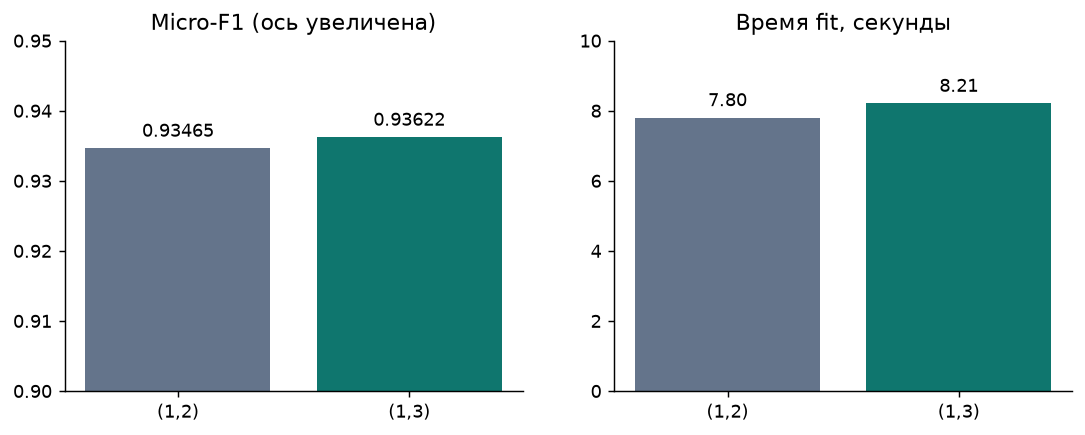

In [2]:
table(['Метрика', 'Биграммы', 'Триграммы', 'Абсолютная Δ', 'Относительная Δ, %'],
      [[r['metric'], f"{r['bigrams']:.6f}", f"{r['trigrams']:.6f}", f"{r['absolute_difference']:+.6f}", f"{r['relative_difference_percent']:+.3f}"] for r in ngrams['comparison']])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, metric, title in zip(axes, ['Micro-F1', 'Training wall time, seconds'], ['Micro-F1 (ось увеличена)', 'Время fit, секунды']):
    r = next(r for r in ngrams['comparison'] if r['metric'] == metric)
    bars = ax.bar(['(1,2)', '(1,3)'], [r['bigrams'], r['trigrams']], color=['#64748b','#0f766e'])
    ax.bar_label(bars, fmt='%.5f' if metric == 'Micro-F1' else '%.2f', padding=4)
    ax.set_title(title)
    if metric == 'Micro-F1': ax.set_ylim(.90,.95)
    else: ax.set_ylim(0,10)
save(fig, '01_word_ngrams.png')

## 2. char_wb и размер словаря на public

Все варианты используют word(1,3), одинаковые пороги и разбиение. sublinear_tf=True уже был исходной настройкой. У вариантов *_linear_tf он выключен отдельно. Лимиты 46k/60k/100k — суммы словесных и символьных признаков.

| Вариант | Micro-F1 | Macro-F1 | P micro | R micro | FP | FN | Fit s | Word/char | Модель MiB |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| baseline | 0.93622 | 0.93623 | 0.93904 | 0.93341 | 111 | 122 | 8.45 | 18000/28000 | 2.75 |
| char_wb | 0.93712 | 0.93720 | 0.93866 | 0.93559 | 112 | 118 | 6.09 | 18000/28000 | 2.75 |
| uncapped_char | 0.92861 | 0.92840 | 0.92709 | 0.93013 | 134 | 128 | 7.70 | 111157/153393 | 12.62 |
| uncapped_char_wb | 0.93479 | 0.93480 | 0.93453 | 0.93504 | 120 | 119 | 5.49 | 111157/68433 | 9.39 |
| char_100k | 0.93100 | 0.93091 | 0.93407 | 0.92795 | 120 | 132 | 8.45 | 40000/60000 | 6.08 |
| char_wb_100k | 0.93435 | 0.93432 | 0.93640 | 0.93231 | 116 | 124 | 5.98 | 40000/60000 | 6.07 |
| char_60k | 0.93326 | 0.93322 | 0.93919 | 0.92740 | 110 | 133 | 8.50 | 24000/36000 | 3.61 |
| char_wb_60k | 0.93534 | 0.93530 | 0.93894 | 0.93177 | 111 | 125 | 6.07 | 24000/36000 | 3.61 |

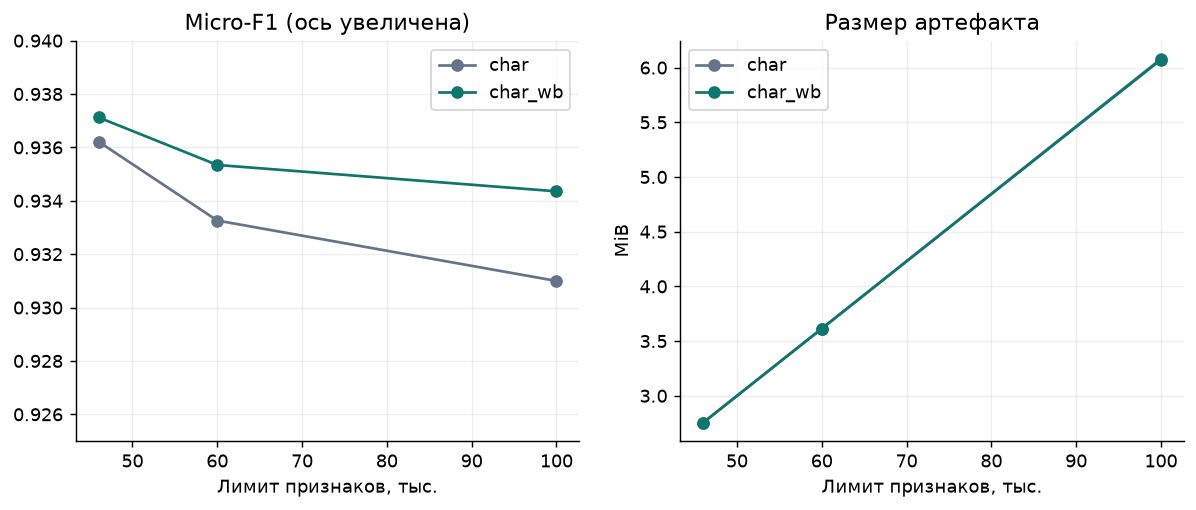

In [3]:
names = features['main_experiments']
table(['Вариант','Micro-F1','Macro-F1','P micro','R micro','FP','FN','Fit s','Word/char','Модель MiB'],
      [[n, *[f"{features['measurements'][n][k]:.5f}" for k in ['micro_f1','macro_f1','micro_precision','micro_recall']],
        features['measurements'][n]['confusion_counts']['fp'], features['measurements'][n]['confusion_counts']['fn'],
        f"{features['measurements'][n]['fit_wall_seconds']:.2f}",
        f"{features['measurements'][n]['dimensions']['word']}/{features['measurements'][n]['dimensions']['char']}",
        f"{features['measurements'][n]['artifact_bytes']/1024**2:.2f}"] for n in names])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for analyzer, ids, color in [('char',['baseline','char_60k','char_100k'],'#64748b'),('char_wb',['char_wb','char_wb_60k','char_wb_100k'],'#0f766e')]:
    axes[0].plot([46,60,100], [features['measurements'][n]['micro_f1'] for n in ids], marker='o', label=analyzer, color=color)
    axes[1].plot([46,60,100], [features['measurements'][n]['artifact_bytes']/1024**2 for n in ids], marker='o', label=analyzer, color=color)
axes[0].set(title='Micro-F1 (ось увеличена)', xlabel='Лимит признаков, тыс.', ylim=(.925,.94))
axes[1].set(title='Размер артефакта', xlabel='Лимит признаков, тыс.', ylabel='MiB')
for ax in axes: ax.legend(); ax.grid(alpha=.2)
save(fig, '02_feature_limits.png')

## 3. Обучение только на v2 и на смеси

v2 train содержит 8464 коротких синтетических примера. После min_df получено лишь 6483 word +4209 char признаков: лимиты 46k/60k/100k неактивны, коэффициенты моделей совпали. Для сравнения на смеси использованы 3398 дедуплицированных public train +8464 v2 train; готовые проверочные части не переделывались.

Показываем качество отдельно на источниках: общий смешанный Micro-F1 не отражает отсутствие деградации на real public.

In [4]:
table(['Смешанная модель', 'Public holdout F1 (729)', 'V2 test F1 (3016)', 'Challenge F1 (40)'],
      [[n, *[f"{m[k]['micro_f1']:.6f}" for k in ['public_test','v2_test','challenge']]] for n,m in mixed['models'].items()])
table(['Корпус','Медиана символов','p95 символов','Медиана слов'],
      [[n,lengths[n]['characters']['median'],lengths[n]['characters']['p95'],lengths[n]['words']['median']]
       for n in ['public_raw','public_dedup_normalized','public_prepared_train','v2_train','v2_test']])
display(Markdown('Синтетика составляет **71.35% документов**, но **21.04% символов** смешанного train. Разница распределений доказана; длина отдельно не доказана как причина изменения F1. См. `output/dataset-length-comparison/lengths.ipynb` и EDA.'))

| Смешанная модель | Public holdout F1 (729) | V2 test F1 (3016) | Challenge F1 (40) |
| --- | --- | --- | --- |
| char_wb | 0.930016 | 0.447005 | 0.488889 |
| char_wb_60k | 0.929685 | 0.443595 | 0.494382 |
| char_wb_100k | 0.924642 | 0.443999 | 0.482759 |

| Корпус | Медиана символов | p95 символов | Медиана слов |
| --- | --- | --- | --- |
| public_raw | 2196.0 | 4960.0 | 285.0 |
| public_dedup_normalized | 1467.0 | 4952.0 | 185.0 |
| public_prepared_train | 1465.0 | 4953.0 | 184.0 |
| v2_train | 143.0 | 409.0 | 19.0 |
| v2_test | 155.0 | 415.0 | 21.0 |

Синтетика составляет **71.35% документов**, но **21.04% символов** смешанного train. Разница распределений доказана; длина отдельно не доказана как причина изменения F1. См. `output/dataset-length-comparison/lengths.ipynb` и EDA.

## 4. Стала ли модель лучше без деградации?

Основная пара имеет одинаковую архитектуру char_wb46k и пороги0.5; отличается только состав обучения. Полный официальный public208 содержит дубли и противоречивые ответы. Дополнительно показана очищенная часть: исключены конфликтующие описания, пересечения со всеми public split и mixed train/calibration, согласованные повторы схлопнуты. Метки не исправлялись.

Очищенная часть меньше и меняет состав проверки, поэтому нужны обе оценки. Эти тесты уже использованы в сравнении; они не являются новым нетронутым финальным набором.

| Набор | Строк | F1 public-only | F1 public+v2 | Δ п.п. | FP old→new | FN old→new |
| --- | --- | --- | --- | --- | --- | --- |
| official_public_208 | 208 | 0.814815 | 0.792169 | -2.265 | 105→106 | 20→32 |
| official_public_clean_unique | 114 | 0.742358 | 0.750000 | +0.764 | 43→44 | 16→14 |
| public_holdout_729 | 729 | 0.937124 | 0.930016 | -0.711 | 112→125 | 118→131 |
| v2_test_3016 | 3016 | 0.355373 | 0.447005 | +9.163 | 781→691 | 3304→2956 |
| challenge_40 | 40 | 0.490196 | 0.488889 | -0.131 | 29→20 | 23→26 |

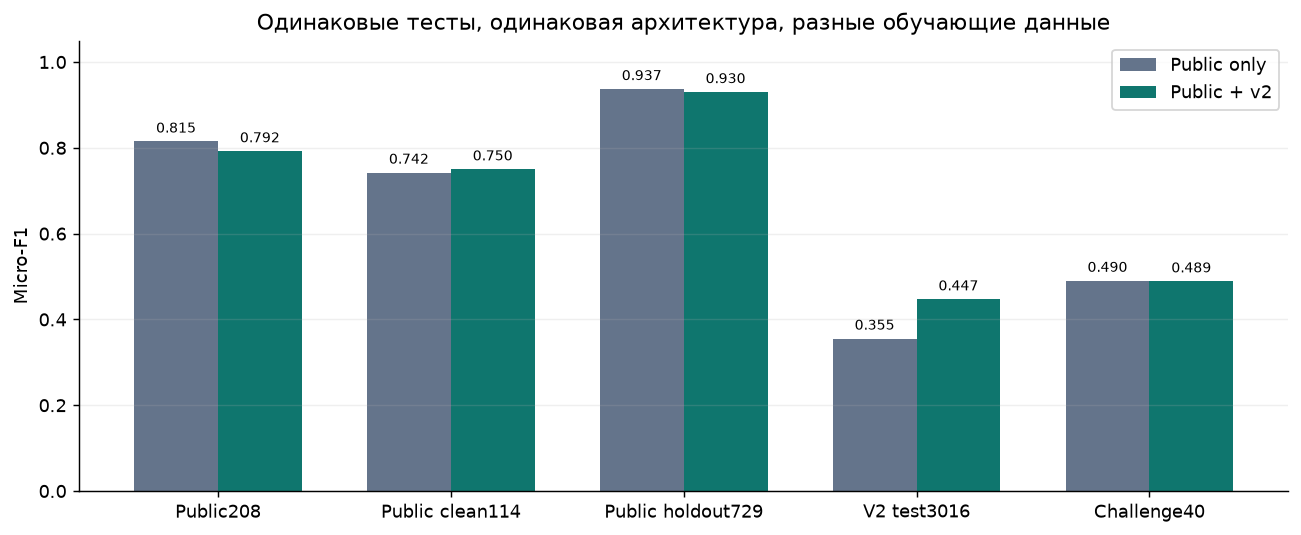

Аудит public208:

{
  "rows": 208,
  "unique_normalized_descriptions": 139,
  "conflicting_description_groups": 13,
  "rows_in_conflicting_groups": 56,
  "rows_overlapping_actual_mixed_train": 20,
  "rows_overlapping_any_public_split": 24,
  "clean_eligible_rows_before_dedup": 132,
  "clean_unique_rows": 114,
  "clean_positive_rows": 41,
  "policy": "Clean subset excludes every conflicting group and all text seen in any public split or mixed train/calibration; then deduplicates consistent labels. No labels corrected."
}


In [5]:
tests = list(paired['comparisons'])
table(['Набор','Строк','F1 public-only','F1 public+v2','Δ п.п.','FP old→new','FN old→new'],
      [[n, r['public_only']['rows'], f"{r['public_only']['micro_f1']:.6f}", f"{r['public_plus_v2']['micro_f1']:.6f}",
        f"{r['delta_new_minus_old']['micro_f1']*100:+.3f}",
        f"{r['public_only']['fp']}→{r['public_plus_v2']['fp']}", f"{r['public_only']['fn']}→{r['public_plus_v2']['fn']}"]
       for n,r in paired['comparisons'].items()])
labels = ['Public208','Public clean114','Public holdout729','V2 test3016','Challenge40']
x = np.arange(len(tests)); width=.36
fig, ax = plt.subplots(figsize=(12,4.5))
for offset, model, title, color in [(-width/2,'public_only','Public only','#64748b'),(width/2,'public_plus_v2','Public + v2','#0f766e')]:
    bars=ax.bar(x+offset,[paired['comparisons'][n][model]['micro_f1'] for n in tests],width,label=title,color=color)
    ax.bar_label(bars,fmt='%.3f',padding=3,fontsize=8)
ax.set(xticks=x,xticklabels=labels,ylabel='Micro-F1',ylim=(0,1.05),title='Одинаковые тесты, одинаковая архитектура, разные обучающие данные')
ax.legend(); ax.grid(axis='y',alpha=.2)
save(fig,'03_old_vs_mixed.png')
display(Markdown('Аудит public208:'))
print(json.dumps(paired['official_audit'],ensure_ascii=False,indent=2))

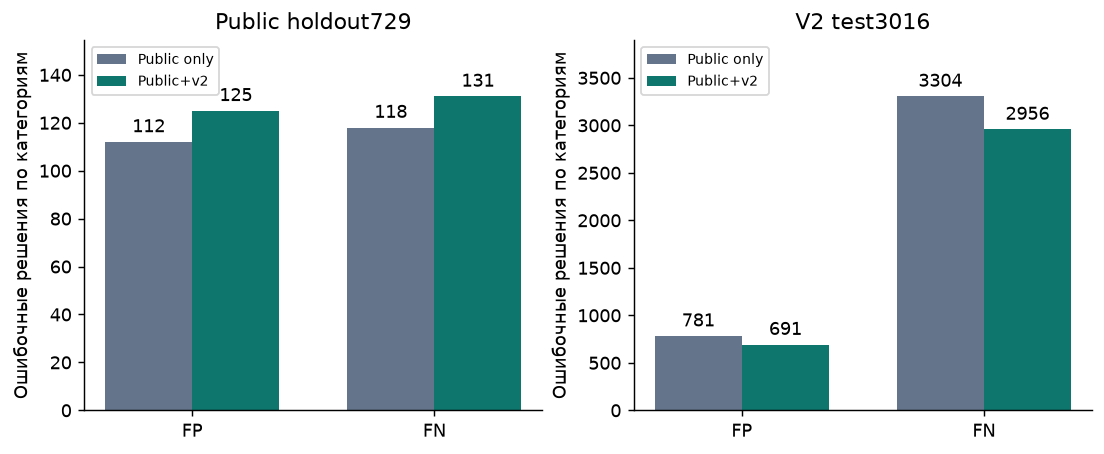

In [6]:
fig, axes=plt.subplots(1,2,figsize=(10,3.7))
for ax,name,title in zip(axes,['public_holdout_729','v2_test_3016'],['Public holdout729','V2 test3016']):
    r=paired['comparisons'][name]
    for offset,model,label,color in [(-.18,'public_only','Public only','#64748b'),(.18,'public_plus_v2','Public+v2','#0f766e')]:
        bars=ax.bar(np.arange(2)+offset,[r[model]['fp'],r[model]['fn']],.36,label=label,color=color)
        ax.bar_label(bars,padding=3)
    ax.set(xticks=[0,1],xticklabels=['FP','FN'],title=title,ylabel='Ошибочные решения по категориям')
    ax.legend(fontsize=8); ax.margins(y=.18)
save(fig,'04_fp_fn.png')

## Вывод и следующий шаг

- `sublinear_tf=True` полезен в выполненных абляциях. Увеличение лимита признаков до60k/100k не улучшило результат; char_wb46k — лучший измеренный кандидат.
- Добавление v2 улучшило его собственный test: Micro-F1 **0.3554→0.4470**, но снизило public holdout **0.9371→0.9300**. Challenge не показал однозначного преимущества. Критерий «лучше на сложных случаях без деградации public» пока не выполнен.
- Public raw и synthetic v2 сильно различаются длиной, лексикой и сложностью. Почти весь v2 содержит отрицания; формальная логика не должна подменять обычный поток.
- Далее: подобрать долю/вес синтетики на реальной validation и отдельно разбирать реалистичные ограничения. Новые архитектурные изменения здесь не проверялись. Рабочую модель не заменяли.

## Происхождение и воспроизведение

Все таблицы читаются из сохранённых measurement/summary JSON в output. Там есть SHA-256 источников/разбиений, версии зависимостей, параметры и время fit. Точное обучение и подготовка описаны в `avito_compare/README.md`; для notebook-воспроизведения установите `requirements-experiments.txt` и запустите `python -m avito_compare.scripts.build_experiment_notebook`.

Старые замеры ссылаются на historical commit0b1be5d и старый путь public в mvp; содержимое public соответствует переносу в datasets/public. Коммиты branch/history связывают дальнейшие изменения. Веса, подготовленные JSONL, NPZ и кэши в Git не добавляются; все исходные датасеты уже находятся в main.